In [5]:
import pandas as pd

# Load the dataset using 'latin1' encoding to bypass the UTF-8 error
df = pd.read_csv('data/emi_prediction_dataset.csv', encoding='latin1')

# 1. Verify it has the required 400,000 records
print(f"Total Records: {len(df)}")

# 2. Verify it contains the 5 specific EMI Scenarios
if 'emi_scenario' in df.columns:
    print("\nEMI Scenarios Found:")
    print(df['emi_scenario'].value_counts())

# 3. Verify both the Classification and Regression target variables exist
required_targets = ['emi_eligibility', 'max_monthly_emi']
missing_targets = [col for col in required_targets if col not in df.columns]

if not missing_targets:
    print("\nSuccess: Both target variables found! This is the correct dataset.")
else:
    print(f"\nWarning: Missing target variables: {missing_targets}")

Total Records: 404830

EMI Scenarios Found:
emi_scenario
Home Appliances EMI        80983
Personal Loan EMI          80977
E-commerce Shopping EMI    80947
Education EMI              80937
Vehicle EMI                80937
Name: count, dtype: int64

Success: Both target variables found! This is the correct dataset.


C:\Users\anush\AppData\Local\Temp\ipykernel_25988\404723387.py:4: DtypeWarning: Columns (0: age, 12: school_fees, 15: groceries_utilities, 18: current_emi_amount) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('data/emi_prediction_dataset.csv', encoding='latin1')


In [6]:
# 1. Reload the data, telling pandas to read the whole file at once to avoid mixed-type guessing
df = pd.read_csv('data/emi_prediction_dataset.csv', encoding='latin1', low_memory=False)
print("Original Shape:", df.shape)

# 2. Remove duplicates
duplicate_count = df.duplicated().sum()
df = df.drop_duplicates()
print(f"Removed {duplicate_count} duplicate rows. New Shape: {df.shape}")

# 3. Fix the mixed data type columns by forcing them to numeric (turning text/errors into NaN)
mixed_cols = ['age', 'school_fees', 'groceries_utilities', 'current_emi_amount']
for col in mixed_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

print("\nMissing values before cleaning:")
print(df.isnull().sum()[df.isnull().sum() > 0]) # Show only columns with missing data

# 4. Fill missing values (Imputation)
# Use median for numbers (ignores extreme outliers) and mode for categories
for col in df.columns:
    if df[col].dtype in ['int64', 'float64']:
        df[col] = df[col].fillna(df[col].median())
    else:
        df[col] = df[col].fillna(df[col].mode()[0])

print(f"\nTotal missing values after cleaning: {df.isnull().sum().sum()}")

Original Shape: (404830, 27)
Removed 6 duplicate rows. New Shape: (404824, 27)

Missing values before cleaning:
age                         43
gender                      36
marital_status              36
education                 2442
monthly_salary              40
employment_type             40
years_of_employment         40
company_type                40
house_type                  40
monthly_rent              2466
family_size                 40
dependents                  40
school_fees                 41
college_fees                40
travel_expenses             40
groceries_utilities         41
other_monthly_expenses      40
existing_loans              41
current_emi_amount          43
credit_score              2463
bank_balance              2469
emergency_fund            2394
emi_scenario                43
requested_amount            43
requested_tenure            43
emi_eligibility             43
max_monthly_emi             43
dtype: int64

Total missing values after cleaning: 

C:\Users\anush\AppData\Local\Temp\ipykernel_25988\2774142179.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='emi_eligibility', palette='viridis')


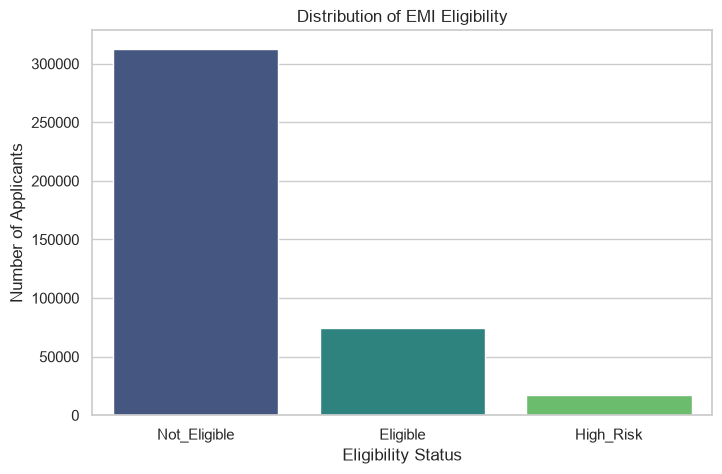

C:\Users\anush\AppData\Local\Temp\ipykernel_25988\2774142179.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, y='emi_scenario', palette='Set2')


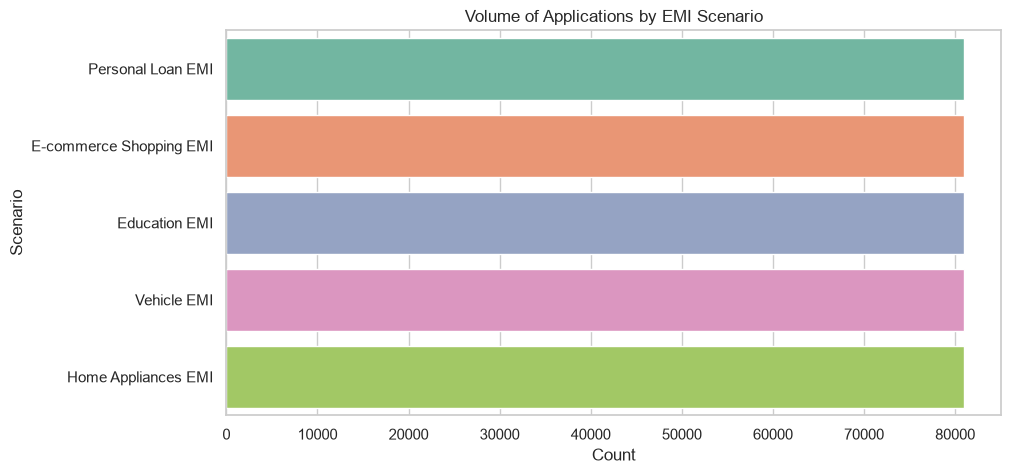

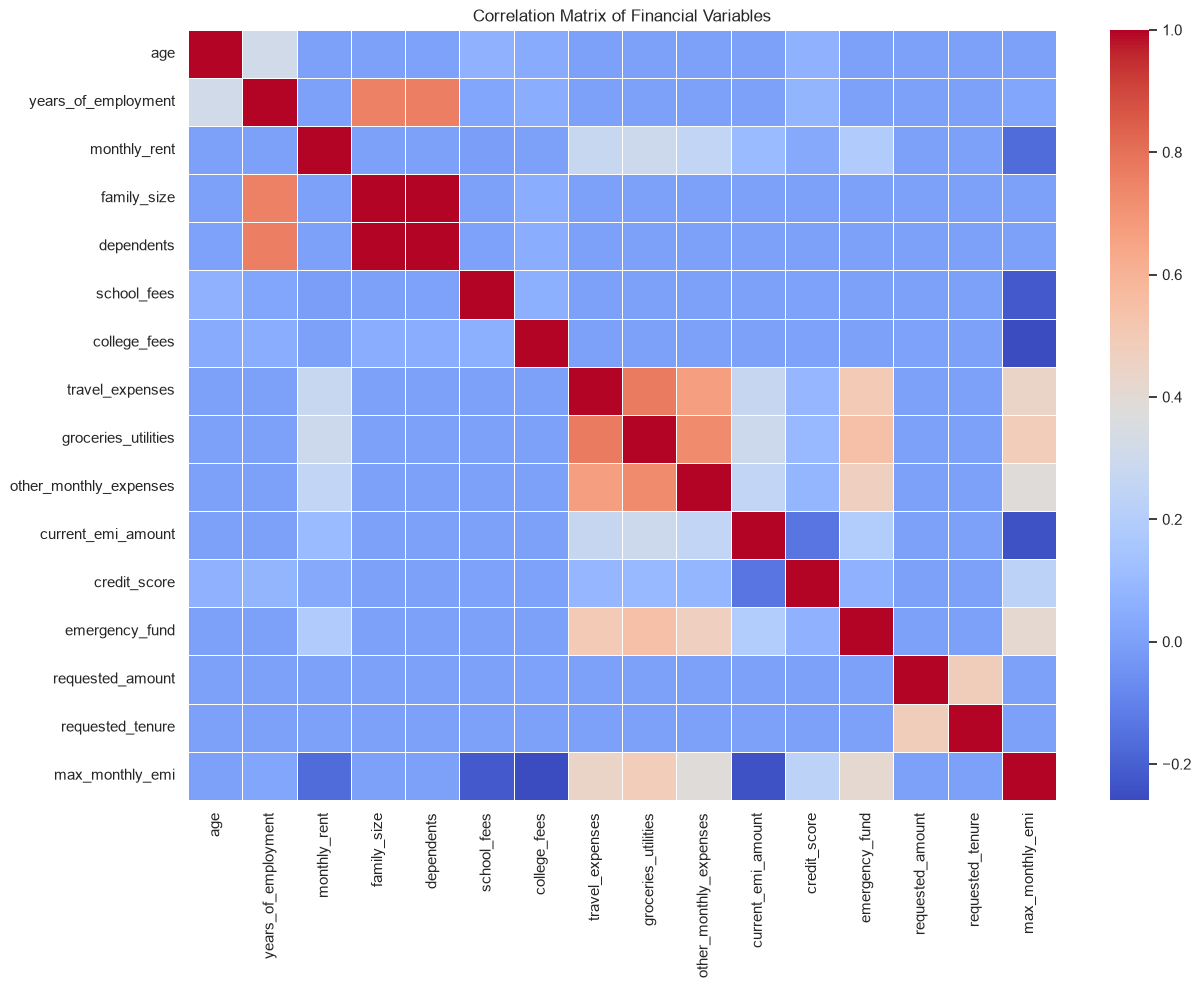

C:\Users\anush\AppData\Local\Temp\ipykernel_25988\2774142179.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='emi_eligibility', y='credit_score', palette='pastel')


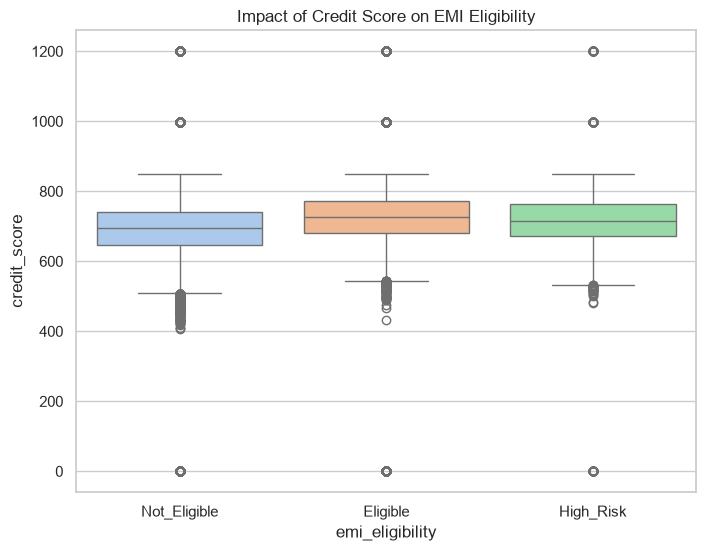

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the visual style for the charts
sns.set_theme(style="whitegrid")

# 1. Distribution of the Classification Target (EMI Eligibility)
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='emi_eligibility', palette='viridis')
plt.title('Distribution of EMI Eligibility')
plt.xlabel('Eligibility Status')
plt.ylabel('Number of Applicants')
plt.show()

# 2. Distribution of the Lending Scenarios
plt.figure(figsize=(10, 5))
sns.countplot(data=df, y='emi_scenario', palette='Set2')
plt.title('Volume of Applications by EMI Scenario')
plt.ylabel('Scenario')
plt.xlabel('Count')
plt.show()

# 3. Correlation Heatmap (Finding relationships between numbers)
plt.figure(figsize=(14, 10))
# Select only the numeric columns for correlation
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns
correlation_matrix = df[numeric_cols].corr()

sns.heatmap(correlation_matrix, annot=False, cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Matrix of Financial Variables')
plt.show()

# 4. Business Insight: Credit Score vs Approval
plt.figure(figsize=(8, 6))
sns.boxplot(data=df, x='emi_eligibility', y='credit_score', palette='pastel')
plt.title('Impact of Credit Score on EMI Eligibility')
plt.show()

In [8]:
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd
import mlflow
import mlflow.sklearn

print("Starting Memory-Safe Feature Engineering...")

# 1. Derived Ratios (Same as before)
expense_cols = ['school_fees', 'college_fees', 'travel_expenses', 
                'groceries_utilities', 'other_monthly_expenses', 
                'monthly_rent', 'current_emi_amount']

for col in expense_cols + ['monthly_salary']:
    df[col] = pd.to_numeric(df[col], errors='coerce').fillna(0)

df['total_monthly_expenses'] = df[expense_cols].sum(axis=1)
df['monthly_salary_safe'] = df['monthly_salary'].replace(0, 1)

df['expense_to_income_ratio'] = df['total_monthly_expenses'] / df['monthly_salary_safe']
df['emi_to_income_ratio'] = df['current_emi_amount'] / df['monthly_salary_safe']
df['savings_capacity'] = df['monthly_salary'] - df['total_monthly_expenses']

df = df.drop(columns=['monthly_salary_safe'])

# 2. Memory-Safe Categorical Encoding (Label Encoding instead of One-Hot)
le_dict = {}
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()

for col in categorical_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col].astype(str))
    le_dict[col] = le # Save encoders for later if needed

# 3. Define Features (X) and Targets (y)
X = df.drop(columns=['emi_eligibility', 'max_monthly_emi'])
y_class = df['emi_eligibility'] # Target 1 for Classification
y_reg = pd.to_numeric(df['max_monthly_emi'], errors='coerce').fillna(0) # Target 2

# 4. Train-Test Split (80% training, 20% testing)
X_train, X_test, y_class_train, y_class_test = train_test_split(X, y_class, test_size=0.2, random_state=42)

# 5. Scale the numerical data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Data prepared! Starting MLflow training...")

# 6. MLflow Integration and Model Training (Classification)
mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("EMI_Eligibility_Classification")

with mlflow.start_run(run_name="Logistic_Regression_Baseline"):
    # Initialize and train the model
    log_reg = LogisticRegression(max_iter=1000)
    log_reg.fit(X_train_scaled, y_class_train)
    
    # Make predictions
    y_pred = log_reg.predict(X_test_scaled)
    
    # Calculate metrics
    accuracy = accuracy_score(y_class_test, y_pred)
    precision = precision_score(y_class_test, y_pred, average='weighted')
    recall = recall_score(y_class_test, y_pred, average='weighted')
    
    print(f"Logistic Regression Accuracy: {accuracy:.4f}")
    
    # Log metrics and model to MLflow
    mlflow.log_param("model_type", "Logistic Regression")
    mlflow.log_metric("accuracy", accuracy)
    mlflow.log_metric("precision", precision)
    mlflow.log_metric("recall", recall)
    
    mlflow.sklearn.log_model(log_reg, "logistic_regression_model")

print("Run complete! Check your MLflow dashboard.")

Starting Memory-Safe Feature Engineering...


C:\Users\anush\AppData\Local\Temp\ipykernel_25988\2860029569.py:30: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include=['object']).columns.tolist()


Data prepared! Starting MLflow training...


2026/10/27 19:06:47 INFO mlflow.tracking.fluent: Experiment with name 'EMI_Eligibility_Classification' does not exist. Creating a new experiment.
2026/10/27 19:06:49 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Logistic Regression Accuracy: 0.8881
Run complete! Check your MLflow dashboard.


In [10]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score
import mlflow
import mlflow.sklearn
import mlflow.xgboost

print("Starting Advanced Model Training...")

# Ensure we are connected to the same database and experiment
mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("EMI_Eligibility_Classification")

# --- 1. Random Forest Classifier ---
print("\nTraining Random Forest (this may take 30-60 seconds)...")
with mlflow.start_run(run_name="Random_Forest_Classifier"):
    # n_jobs=-1 uses all your CPU cores to speed up training
    rf_model = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
    rf_model.fit(X_train_scaled, y_class_train)
    
    y_pred_rf = rf_model.predict(X_test_scaled)
    
    acc_rf = accuracy_score(y_class_test, y_pred_rf)
    prec_rf = precision_score(y_class_test, y_pred_rf, average='weighted', zero_division=0)
    rec_rf = recall_score(y_class_test, y_pred_rf, average='weighted', zero_division=0)
    
    print(f"Random Forest Accuracy: {acc_rf:.4f}")
    
    # Log to MLflow
    mlflow.log_param("model_type", "Random Forest")
    mlflow.log_param("n_estimators", 100)
    mlflow.log_param("max_depth", 10)
    mlflow.log_metric("accuracy", acc_rf)
    mlflow.log_metric("precision", prec_rf)
    mlflow.log_metric("recall", rec_rf)
    
    # THE FIX: Tell MLflow to bypass the skops security check using cloudpickle
    mlflow.sklearn.log_model(
        rf_model, 
        "random_forest_model",
        serialization_format="cloudpickle"
    )

# --- 2. XGBoost Classifier ---
print("\nTraining XGBoost...")
with mlflow.start_run(run_name="XGBoost_Classifier"):
    xgb_model = XGBClassifier(n_estimators=100, max_depth=6, learning_rate=0.1, random_state=42, n_jobs=-1)
    xgb_model.fit(X_train_scaled, y_class_train)
    
    y_pred_xgb = xgb_model.predict(X_test_scaled)
    
    acc_xgb = accuracy_score(y_class_test, y_pred_xgb)
    prec_xgb = precision_score(y_class_test, y_pred_xgb, average='weighted', zero_division=0)
    rec_xgb = recall_score(y_class_test, y_pred_xgb, average='weighted', zero_division=0)
    
    print(f"XGBoost Accuracy: {acc_xgb:.4f}")
    
    # Log to MLflow
    mlflow.log_param("model_type", "XGBoost")
    mlflow.log_param("n_estimators", 100)
    mlflow.log_param("max_depth", 6)
    mlflow.log_param("learning_rate", 0.1)
    mlflow.log_metric("accuracy", acc_xgb)
    mlflow.log_metric("precision", prec_xgb)
    mlflow.log_metric("recall", rec_xgb)
    mlflow.xgboost.log_model(xgb_model, "xgboost_model")

print("\nAdvanced Training Complete! Check your MLflow dashboard to compare the models.")

Starting Advanced Model Training...

Training Random Forest (this may take 30-60 seconds)...


2026/10/27 19:10:46 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/27 19:10:46 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Random Forest Accuracy: 0.9175

Training XGBoost...


2026/10/27 19:10:58 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


XGBoost Accuracy: 0.9533

Advanced Training Complete! Check your MLflow dashboard to compare the models.
